# 02 Cleaning and EDA

Creates cleaning log, report-ready figures, and `daily_panel_clean.csv`.

Every figure is saved under `notebooks/outputs/latest/figures/` with an insight note for the interim report.


In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from project_paths import load_env, ensure_output_dirs
ROOT = load_env()
PATHS = ensure_output_dirs(ROOT)
print("ROOT", ROOT)
print({k: str(v) for k, v in PATHS.items()})


ROOT /Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold
{'root': '/Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold', 'raw': '/Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold/data/raw', 'processed': '/Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold/data/processed', 'outputs': '/Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold/notebooks/outputs/latest', 'figures': '/Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold/notebooks/outputs/latest/figures', 'tables': '/Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold/notebooks/outputs/latest/tables'}


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk")
panel_path = PATHS["processed"] / "daily_panel.csv"
df = pd.read_csv(panel_path, parse_dates=["date"]).sort_values("date")
print(df.shape)
df.head()


(2113, 23)


,date,wti_spot,brent_spot,natgas_hh,wheat,corn,soy,gdelt_tone,commodity_roll_yield,grain_calendar_spread,...,vessel_draught_anomaly,tanker_transit_count,physical_iv_note,source_notes,bottleneck_index_5d,volatility_regime,omega_ratio_proxy,news_event_impact_score,finbert_risk_probability,finbert_headline_n
0,2021-01-01,NaN,NaN,NaN,237.94425,231.754461,510.669604,NaN,NaN,6.189788,...,-1.113608,188,PortWatch ArcGIS Daily_Chokepoints_Data: choke...,portwatch_arcgis_merged,0.260130,0,NaN,NaN,0.156146,0.0
1,2021-01-02,NaN,NaN,NaN,237.94425,231.754461,510.669604,NaN,NaN,6.189788,...,0.415315,195,PortWatch ArcGIS Daily_Chokepoints_Data: choke...,portwatch_arcgis_merged,0.268035,0,NaN,NaN,0.156146,0.0
2,2021-01-03,NaN,NaN,NaN,237.94425,231.754461,510.669604,NaN,NaN,6.189788,...,-0.512966,192,PortWatch ArcGIS Daily_Chokepoints_Data: choke...,portwatch_arcgis_merged,0.232815,0,NaN,NaN,0.156146,0.0
3,2021-01-04,47.47,50.37,2.60,237.94425,231.754461,510.669604,NaN,NaN,6.189788,...,-1.403123,170,PortWatch ArcGIS Daily_Chokepoints_Data: choke...,portwatch_arcgis_merged,0.129980,0,NaN,NaN,0.156146,0.0
4,2021-01-05,49.78,53.16,2.77,237.94425,231.754461,510.669604,NaN,NaN,6.189788,...,0.170493,195,PortWatch ArcGIS Daily_Chokepoints_Data: choke...,portwatch_arcgis_merged,0.439472,0,NaN,NaN,0.156146,0.0


In [3]:
# Cleaning log
cleaning_rows = []
n0 = len(df)

# Drop rows with no date or no WTI (core market anchor)
before = len(df)
df = df.dropna(subset=["date", "wti_spot"])
cleaning_rows.append({
    "Issue": "Missing core market anchor",
    "Variables Affected": "date,wti_spot",
    "Detection Method": "isna",
    "Treatment Applied": f"drop {before-len(df)} rows",
    "Rationale": "Cannot model commodity outcomes without observed WTI",
})

# Duplicates
dup = df.duplicated(subset=["date"]).sum()
df = df.drop_duplicates(subset=["date"], keep="last")
cleaning_rows.append({
    "Issue": "Duplicates",
    "Variables Affected": "date",
    "Detection Method": "duplicated(date)",
    "Treatment Applied": f"drop {dup} duplicate dates",
    "Rationale": "One row per day for panel models",
})

# Winsorize extreme return outliers on WTI
ret = df["wti_spot"].pct_change()
lo, hi = ret.quantile(0.01), ret.quantile(0.99)
mask = ret.between(lo, hi) | ret.isna()
removed = (~mask).sum()
df = df.loc[mask | ret.isna()].copy()
cleaning_rows.append({
    "Issue": "Outliers",
    "Variables Affected": "wti_spot returns",
    "Detection Method": "1st/99th pct return fences",
    "Treatment Applied": f"remove {removed} extreme return days",
    "Rationale": "Limit distortion from bad ticks while keeping real crisis days inside fences",
})

# Forward/back fill limited gaps on key numeric columns
num_cols = df.select_dtypes("number").columns
miss_before = df[num_cols].isna().sum()
df[num_cols] = df[num_cols].ffill(limit=3).bfill(limit=1)
miss_after = df[num_cols].isna().sum()
cleaning_rows.append({
    "Issue": "Missing values",
    "Variables Affected": ",".join(num_cols[:8]) + ",...",
    "Detection Method": "isna sum",
    "Treatment Applied": "ffill limit 3, bfill limit 1",
    "Rationale": "Preserve chronology; avoid long leakage-style fills",
})

df = df.reset_index(drop=True)
clean_path = PATHS["processed"] / "daily_panel_clean.csv"
df.to_csv(clean_path, index=False)
log = pd.DataFrame(cleaning_rows)
log_path = PATHS["tables"] / "cleaning_log.csv"
log.to_csv(log_path, index=False)
print("Wrote", clean_path, "rows", len(df), "from", n0)
log


Wrote /Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold/data/processed/daily_panel_clean.csv rows 2066 from 2113


,Issue,Variables Affected,Detection Method,Treatment Applied,Rationale
0,Missing core market anchor,"date,wti_spot",isna,drop 3 rows,Cannot model commodity outcomes without observ...
1,Duplicates,date,duplicated(date),drop 0 duplicate dates,One row per day for panel models
2,Outliers,wti_spot returns,1st/99th pct return fences,remove 44 extreme return days,Limit distortion from bad ticks while keeping ...
3,Missing values,"wti_spot,brent_spot,natgas_hh,wheat,corn,soy,g...",isna sum,"ffill limit 3, bfill limit 1",Preserve chronology; avoid long leakage-style ...


### Figure 1. Missingness after cleaning

Insight: shows which synopsis variables still need coverage (especially PortWatch physical IVs).


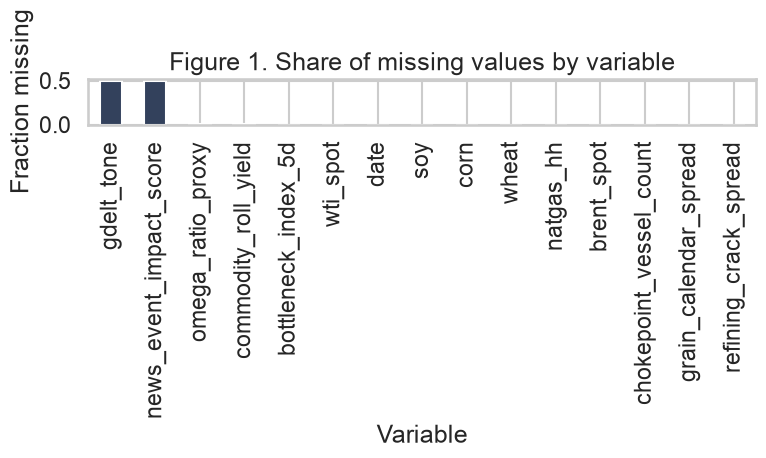

In [4]:
miss = df.isna().mean().sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(8, 4.5))
miss.plot(kind="bar", ax=ax, color="#33415c")
ax.set_title("Figure 1. Share of missing values by variable")
ax.set_ylabel("Fraction missing")
ax.set_xlabel("Variable")
fig.tight_layout()
fig.savefig(PATHS["figures"] / "fig01_missingness.png", dpi=200)
plt.show()


### Figure 2. WTI and congestion / stress series

Supports RQ1 physical-friction vs market stress timing.


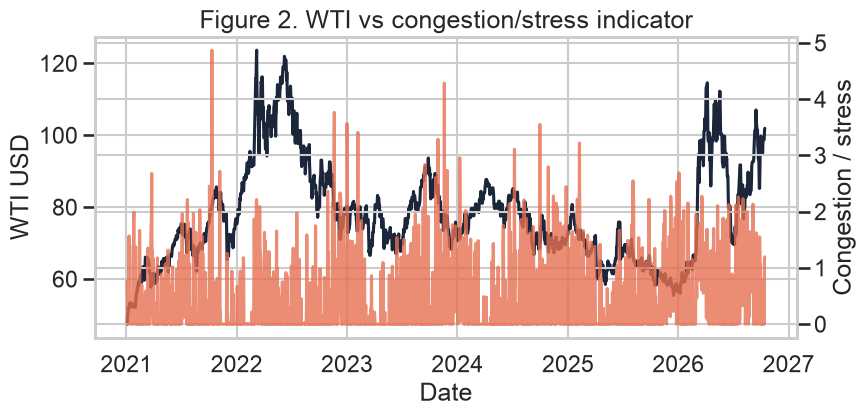

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(df["date"], df["wti_spot"], label="WTI spot", color="#1b263b")
ax2 = ax.twinx()
ax2.plot(df["date"], df["port_congestion_hours"], label="Congestion/stress", color="#e76f51", alpha=0.8)
ax.set_title("Figure 2. WTI vs congestion/stress indicator")
ax.set_xlabel("Date")
ax.set_ylabel("WTI USD")
ax2.set_ylabel("Congestion / stress")
fig.tight_layout()
fig.savefig(PATHS["figures"] / "fig02_wti_congestion.png", dpi=200)
plt.show()


### Figure 3. Correlation heatmap (RQ-linked features)


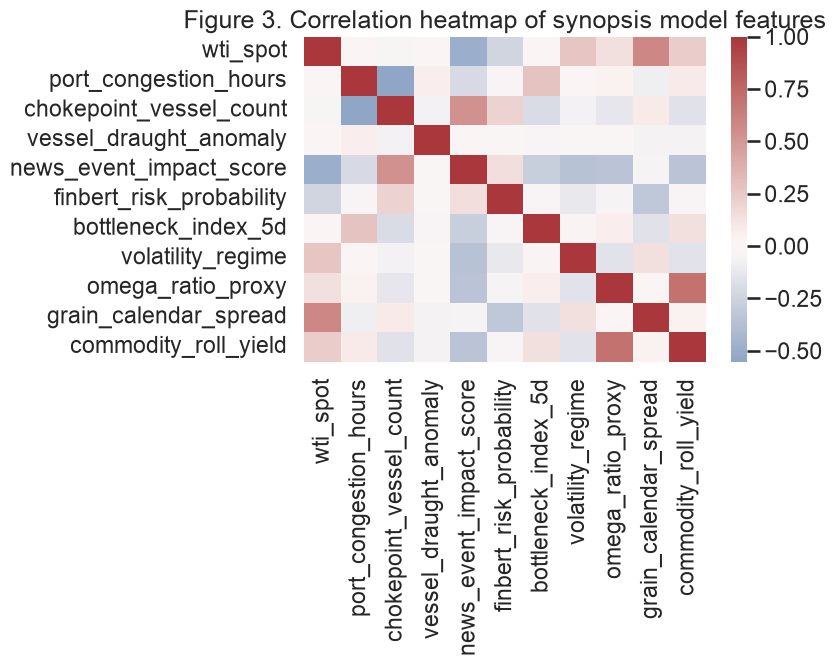

In [6]:
cols = [c for c in [
    "wti_spot","port_congestion_hours","chokepoint_vessel_count","vessel_draught_anomaly",
    "news_event_impact_score","finbert_risk_probability","bottleneck_index_5d",
    "volatility_regime","omega_ratio_proxy","grain_calendar_spread","commodity_roll_yield"
] if c in df.columns]
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr, ax=ax, cmap="vlag", center=0, annot=False)
ax.set_title("Figure 3. Correlation heatmap of synopsis model features")
fig.tight_layout()
fig.savefig(PATHS["figures"] / "fig03_corr_heatmap.png", dpi=200)
plt.show()


In [7]:
# EDA insight summary table for interim template
eda = pd.DataFrame([
    {"Figure/Table Reference": "Figure 1", "What it Shows": "Missingness by variable", "Key Insight": "Identify incomplete PortWatch vs market coverage", "Why it Matters (Link to RQ/objective)": "RQ1 physical IV completeness", "Decision/Next Step": "Add PortWatch CSV if vessel fields sparse"},
    {"Figure/Table Reference": "Figure 2", "What it Shows": "WTI vs congestion/stress", "Key Insight": "Co-movement during stress windows", "Why it Matters (Link to RQ/objective)": "RQ1/RQ3 timing", "Decision/Next Step": "Use lags in forecast models"},
    {"Figure/Table Reference": "Figure 3", "What it Shows": "Feature correlations", "Key Insight": "Which IVs move with targets", "Why it Matters (Link to RQ/objective)": "Feature selection RQ1-RQ3", "Decision/Next Step": "Drop near-duplicate predictors"},
])
eda.to_csv(PATHS["tables"] / "eda_insight_summary.csv", index=False)
eda


,Figure/Table Reference,What it Shows,Key Insight,Why it Matters (Link to RQ/objective),Decision/Next Step
0,Figure 1,Missingness by variable,Identify incomplete PortWatch vs market coverage,RQ1 physical IV completeness,Add PortWatch CSV if vessel fields sparse
1,Figure 2,WTI vs congestion/stress,Co-movement during stress windows,RQ1/RQ3 timing,Use lags in forecast models
2,Figure 3,Feature correlations,Which IVs move with targets,Feature selection RQ1-RQ3,Drop near-duplicate predictors
